In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Nicer default plots
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.titlesize"] = 12

DATA = Path("../data/raw/malawi_households_hourly.csv")
df = pd.read_csv(DATA, parse_dates=["timestamp"])

print(f"Rows: {len(df):,}")
print(f"Households: {df.household_id.nunique()}")
print(f"Time span: {df.timestamp.min()} → {df.timestamp.max()}")
print(f"\nColumns:\n{df.dtypes}")

# Aggregate to household level
hh = df.groupby("household_id").agg(
    area=("area", "first"),
    region=("region", "first"),
    household_size=("household_size", "first"),
    total_kwh=("consumption_kwh", "sum"),
    mean_hourly_kwh=("consumption_kwh", "mean"),
    std_hourly_kwh=("consumption_kwh", "std"),
    max_hourly_kwh=("consumption_kwh", "max"),
    load_shed_frac=("load_shed", "mean"),
).reset_index()

# Daily average (365 days)
hh["mean_daily_kwh"] = hh["total_kwh"] / 365

# Coefficient of variation: how spiky is this household's behavior?
hh["volatility_cv"] = hh["std_hourly_kwh"] / hh["mean_hourly_kwh"].replace(0, np.nan)

print(hh.shape)   # (200, 11)
hh.head()

Rows: 1,752,000
Households: 200
Time span: 2024-01-01 00:00:00 → 2024-12-30 23:00:00

Columns:
household_id                int64
timestamp          datetime64[us]
region                        str
area                          str
household_size              int64
consumption_kwh           float64
is_weekend                  int64
is_rainy_season             int64
load_shed                   int64
hour                        int64
day_of_week                 int64
month                       int64
dtype: object
(200, 11)


,household_id,area,region,household_size,total_kwh,mean_hourly_kwh,std_hourly_kwh,max_hourly_kwh,load_shed_frac,mean_daily_kwh,volatility_cv
0,0,rural,South,3,200.9146,0.022935,0.051934,0.2839,0.039155,0.550451,2.264348
1,1,urban,South,5,1997.0522,0.227974,0.842411,12.4528,0.039155,5.471376,3.695207
2,2,rural,South,6,300.3854,0.034291,0.065660,0.2517,0.039155,0.822974,1.914821
3,3,rural,Central,2,671.1772,0.076618,0.291388,4.5848,0.039155,1.838842,3.803107
4,4,urban,South,6,862.5592,0.098466,0.710254,10.6159,0.039155,2.363176,7.213213


In [2]:
# Compute household-level hourly profiles (200 × 24 matrix)
hourly_profile = (df.groupby(["household_id", "hour"])["consumption_kwh"]
                    .mean()
                    .unstack("hour"))   # rows = household, columns = hour 0..23
print(hourly_profile.shape)   # (200, 24)
hourly_profile.iloc[:3, :6]   # peek

(200, 24)


hour,0,1,2,3,4,5
household_id,,,,,,
0,0.017901,0.015542,0.012095,0.015997,0.014744,0.019325
1,0.065691,0.042214,0.046832,0.039056,0.042052,0.033435
2,0.007242,0.003195,0.004494,0.002344,0.005616,0.012295


In [3]:
# Normalize each row so we get the SHAPE (fractions sum to 1), not the LEVEL
# This separates "when" from "how much"
shape = hourly_profile.div(hourly_profile.sum(axis=1), axis=0)
shape.columns = [f"h{h}" for h in shape.columns]   # rename for readability

# Key shape features
def _agg_shape(row):
    return pd.Series({
        "night_ratio":   row[["h0","h1","h2","h3","h4"]].sum(),
        "morning_ratio": row[["h5","h6","h7","h8","h9"]].sum(),
        "midday_ratio":  row[["h10","h11","h12","h13","h14"]].sum(),
        "evening_ratio": row[["h15","h16","h17","h18","h19","h20","h21","h22"]].sum(),
        "peak_hour_18_20": row[["h18","h19","h20"]].sum(),
    })

shape_feats = shape.apply(_agg_shape, axis=1).reset_index()
shape_feats.head()

,household_id,night_ratio,morning_ratio,midday_ratio,evening_ratio,peak_hour_18_20
0,0,0.138573,0.182300,0.139512,0.503635,0.270488
1,1,0.043105,0.211797,0.104274,0.631640,0.426826
2,2,0.027816,0.090932,0.280393,0.585441,0.229228
3,3,0.065256,0.184225,0.081626,0.656596,0.422157
4,4,0.066511,0.320668,0.117640,0.476733,0.343449


In [4]:
# Weekend lift
weekend = (df.groupby(["household_id", "is_weekend"])["consumption_kwh"]
             .mean()
             .unstack("is_weekend"))
weekend.columns = ["weekday", "weekend"]
weekend["weekend_lift"] = weekend["weekend"] / weekend["weekday"].replace(0, np.nan)

# Seasonal swing
season = (df.groupby(["household_id", "is_rainy_season"])["consumption_kwh"]
            .mean()
            .unstack("is_rainy_season"))
season.columns = ["dry", "rainy"]
season["seasonal_swing"] = season["rainy"] / season["dry"].replace(0, np.nan)

weekend_season_feats = pd.concat([
    weekend[["weekend_lift"]],
    season[["seasonal_swing"]]
], axis=1).reset_index()
weekend_season_feats.head()

,household_id,weekend_lift,seasonal_swing
0,0,1.127361,1.113704
1,1,1.226505,1.067393
2,2,1.122723,0.796919
3,3,0.912214,1.027967
4,4,1.108872,0.986408


In [5]:
household_features = (hh
    .merge(shape_feats, on="household_id")
    .merge(weekend_season_feats, on="household_id")
    .drop(columns=["total_kwh", "std_hourly_kwh"])   # keep mean_hourly + max
)

# Flag urban as binary for coloring later (NOT for clustering!)
household_features["is_urban"] = (household_features["area"] == "urban").astype(int)

print(household_features.shape)
household_features.head()

(200, 17)


,household_id,area,region,household_size,mean_hourly_kwh,max_hourly_kwh,load_shed_frac,mean_daily_kwh,volatility_cv,night_ratio,morning_ratio,midday_ratio,evening_ratio,peak_hour_18_20,weekend_lift,seasonal_swing,is_urban
0,0,rural,South,3,0.022935,0.2839,0.039155,0.550451,2.264348,0.138573,0.182300,0.139512,0.503635,0.270488,1.127361,1.113704,0
1,1,urban,South,5,0.227974,12.4528,0.039155,5.471376,3.695207,0.043105,0.211797,0.104274,0.631640,0.426826,1.226505,1.067393,1
2,2,rural,South,6,0.034291,0.2517,0.039155,0.822974,1.914821,0.027816,0.090932,0.280393,0.585441,0.229228,1.122723,0.796919,0
3,3,rural,Central,2,0.076618,4.5848,0.039155,1.838842,3.803107,0.065256,0.184225,0.081626,0.656596,0.422157,0.912214,1.027967,0
4,4,urban,South,6,0.098466,10.6159,0.039155,2.363176,7.213213,0.066511,0.320668,0.117640,0.476733,0.343449,1.108872,0.986408,1


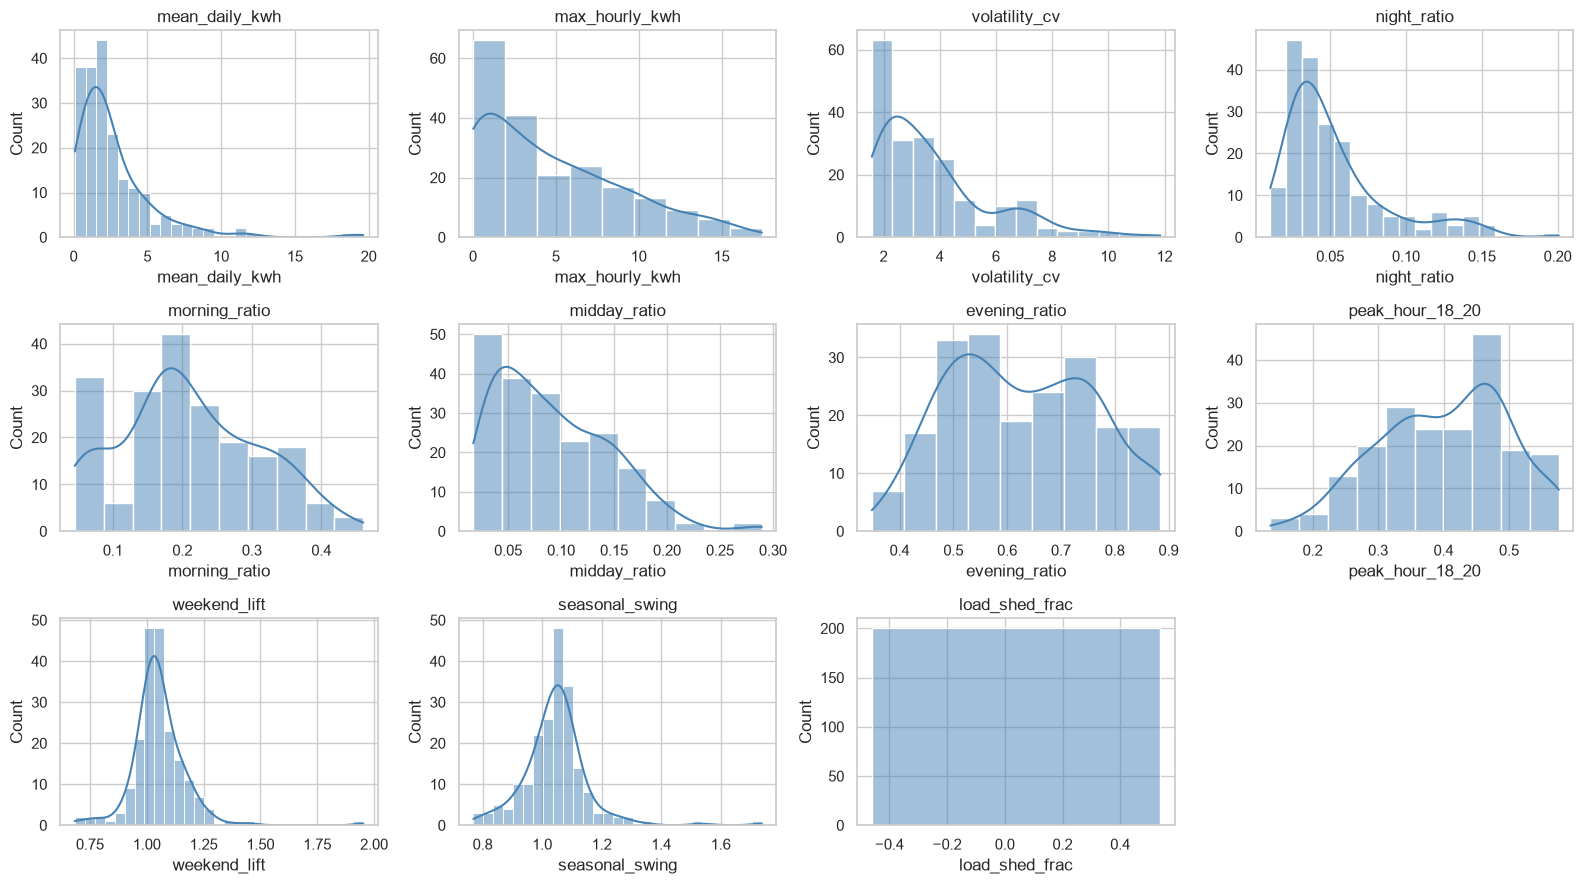

In [6]:
numeric_cols = [
    "mean_daily_kwh", "max_hourly_kwh", "volatility_cv",
    "night_ratio", "morning_ratio", "midday_ratio", "evening_ratio",
    "peak_hour_18_20", "weekend_lift", "seasonal_swing", "load_shed_frac"
]

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for col, ax in zip(numeric_cols, axes.flatten()):
    sns.histplot(household_features[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
axes.flatten()[-1].axis("off")   # hide empty last subplot
plt.tight_layout()
plt.show()

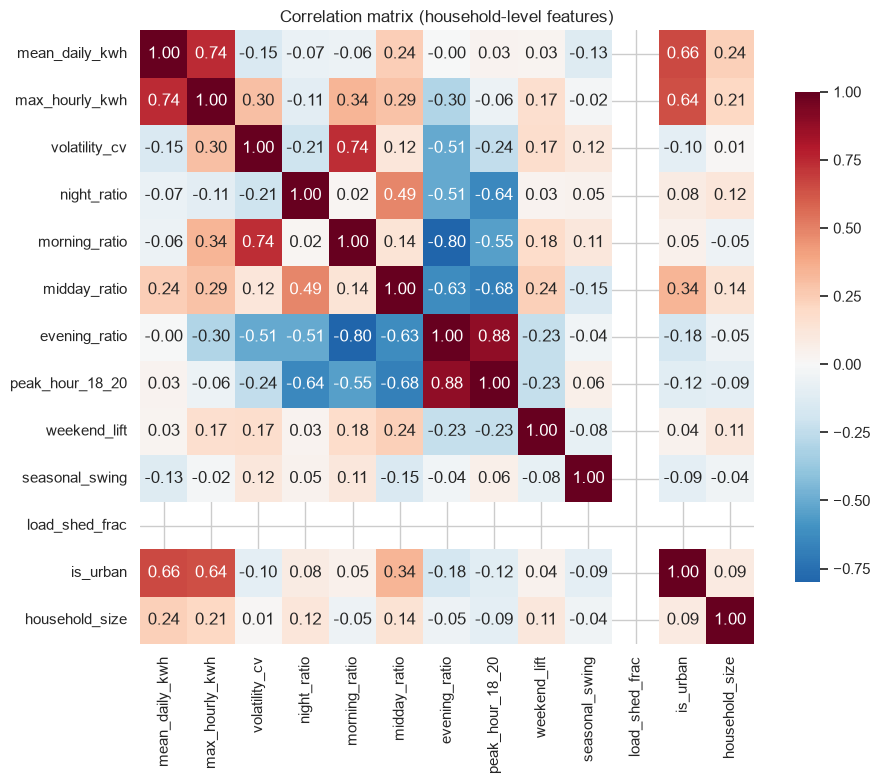

In [7]:
corr = household_features[numeric_cols + ["is_urban", "household_size"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix (household-level features)")
plt.tight_layout()
plt.show()

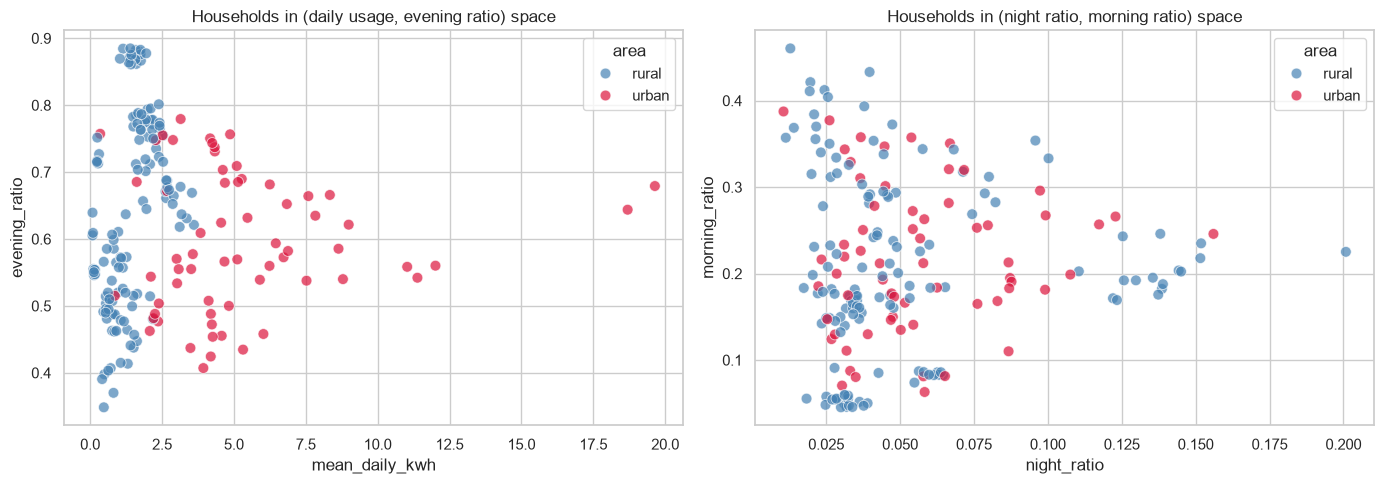

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# The single most informative scatter
sns.scatterplot(data=household_features, x="mean_daily_kwh", y="evening_ratio",
                hue="area", palette={"urban": "crimson", "rural": "steelblue"},
                s=60, alpha=0.7, ax=axes[0])
axes[0].set_title("Households in (daily usage, evening ratio) space")

# Same but colored by weekday profile
sns.scatterplot(data=household_features, x="night_ratio", y="morning_ratio",
                hue="area", palette={"urban": "crimson", "rural": "steelblue"},
                s=60, alpha=0.7, ax=axes[1])
axes[1].set_title("Households in (night ratio, morning ratio) space")

plt.tight_layout()
plt.show()

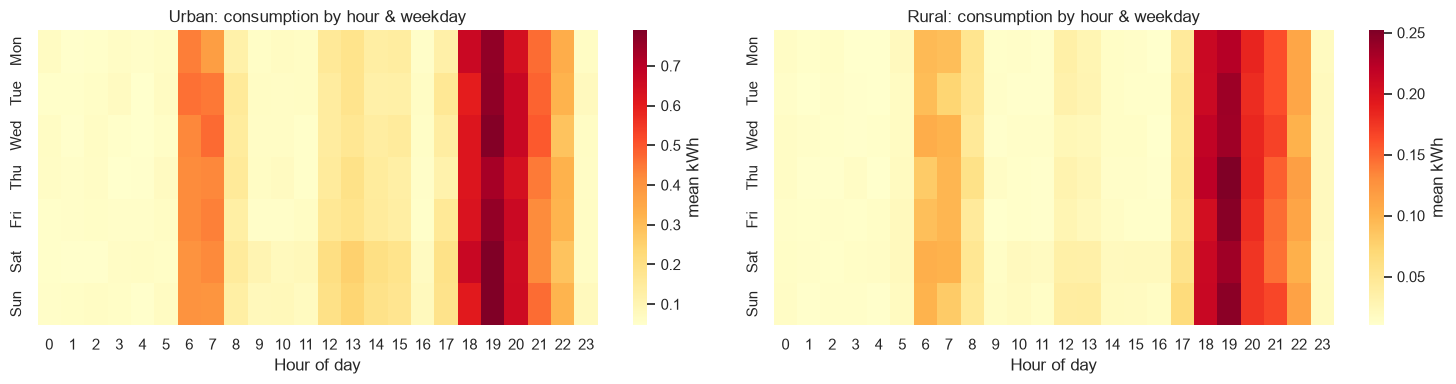

In [9]:
# Aggregate the full dataset by (day_of_week, hour, area)
heat = (df.groupby(["area", "day_of_week", "hour"])["consumption_kwh"]
          .mean()
          .unstack("hour"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

for ax, area in zip(axes, ["urban", "rural"]):
    sns.heatmap(heat.loc[area], cmap="YlOrRd", ax=ax,
                yticklabels=day_labels, cbar_kws={"label": "mean kWh"})
    ax.set_title(f"{area.capitalize()}: consumption by hour & weekday")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

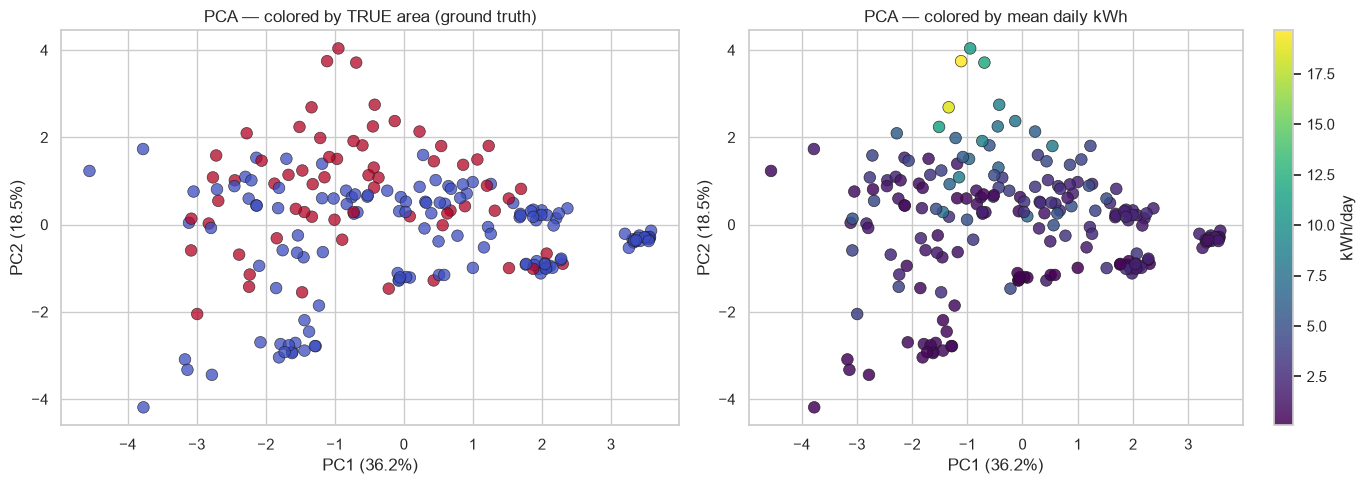

PC1 captures 36.2% of variance
PC2 captures 18.5% of variance
Together: 54.6%


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

cluster_cols = [
    "mean_daily_kwh", "max_hourly_kwh", "volatility_cv",
    "night_ratio", "morning_ratio", "midday_ratio", "evening_ratio",
    "peak_hour_18_20", "weekend_lift", "seasonal_swing", "load_shed_frac",
]

X = household_features[cluster_cols].values

# Scale — essential for distance-based methods
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA to 2D for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By area (ground truth we hope to rediscover)
axes[0].scatter(X_2d[:, 0], X_2d[:, 1],
                c=household_features["is_urban"],
                cmap="coolwarm", s=70, alpha=0.75, edgecolor="k", linewidth=0.5)
axes[0].set_title("PCA — colored by TRUE area (ground truth)")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")

# By mean daily usage (for intuition)
sc = axes[1].scatter(X_2d[:, 0], X_2d[:, 1],
                     c=household_features["mean_daily_kwh"],
                     cmap="viridis", s=70, alpha=0.85, edgecolor="k", linewidth=0.5)
axes[1].set_title("PCA — colored by mean daily kWh")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.colorbar(sc, ax=axes[1], label="kWh/day")

plt.tight_layout()
plt.show()

print(f"PC1 captures {pca.explained_variance_ratio_[0]:.1%} of variance")
print(f"PC2 captures {pca.explained_variance_ratio_[1]:.1%} of variance")
print(f"Together: {pca.explained_variance_ratio_[:2].sum():.1%}")

In [11]:
PROC = Path("../data/processed")
PROC.mkdir(exist_ok=True)

# The clean household-level feature table
household_features.to_csv(PROC / "household_features.csv", index=False)

# Save the scaler & feature column list for reuse in clustering
import joblib
joblib.dump({"scaler": scaler, "feature_cols": cluster_cols},
            PROC / "scaler_and_features.joblib")

print(f"Saved household_features.csv  shape={household_features.shape}")
print(f"Saved scaler_and_features.joblib")
print(f"\nFeatures used for clustering ({len(cluster_cols)}):")
for c in cluster_cols:
    print(f"  • {c}")

Saved household_features.csv  shape=(200, 17)
Saved scaler_and_features.joblib

Features used for clustering (11):
  • mean_daily_kwh
  • max_hourly_kwh
  • volatility_cv
  • night_ratio
  • morning_ratio
  • midday_ratio
  • evening_ratio
  • peak_hour_18_20
  • weekend_lift
  • seasonal_swing
  • load_shed_frac


In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

hh = pd.read_csv("../data/processed/household_features.csv")

# 1. Numeric summary by area
numeric_cols = [
    "mean_daily_kwh", "max_hourly_kwh", "volatility_cv",
    "night_ratio", "morning_ratio", "midday_ratio", "evening_ratio",
    "peak_hour_18_20", "weekend_lift", "seasonal_swing", "load_shed_frac",
]

print("=== Mean by area ===")
print(hh.groupby("area")[numeric_cols].mean().T.round(3))

print("\n=== Std by area (spread within group) ===")
print(hh.groupby("area")[numeric_cols].std().T.round(3))

print("\n=== Zero-variance check ===")
variances = hh[numeric_cols].var()
print(variances[variances < 1e-6])

=== Mean by area ===
area             rural  urban
mean_daily_kwh   1.441  5.332
max_hourly_kwh   2.790  8.714
volatility_cv    3.884  3.471
night_ratio      0.051  0.057
morning_ratio    0.205  0.216
midday_ratio     0.079  0.118
evening_ratio    0.645  0.595
peak_hour_18_20  0.410  0.386
weekend_lift     1.050  1.060
seasonal_swing   1.051  1.030
load_shed_frac   0.039  0.039

=== Std by area (spread within group) ===
area             rural  urban
mean_daily_kwh   0.835  3.483
max_hourly_kwh   2.711  4.329
volatility_cv    2.282  1.308
night_ratio      0.036  0.028
morning_ratio    0.105  0.083
midday_ratio     0.054  0.043
evening_ratio    0.146  0.102
peak_hour_18_20  0.104  0.079
weekend_lift     0.133  0.092
seasonal_swing   0.115  0.093
load_shed_frac   0.000  0.000

=== Zero-variance check ===
load_shed_frac    0.0
dtype: float64


=== Correlation: level features ===
                mean_daily_kwh  max_hourly_kwh
mean_daily_kwh           1.000           0.742
max_hourly_kwh           0.742           1.000


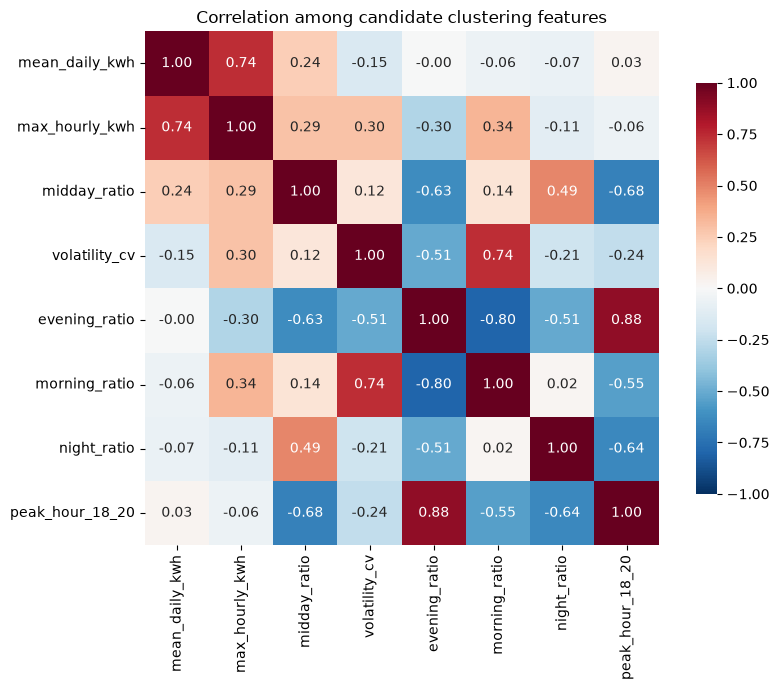

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- Load the data (this was the missing part) ---
hh = pd.read_csv("../data/processed/household_features.csv")

# --- Correlation: level features ---
print("=== Correlation: level features ===")
print(hh[["mean_daily_kwh", "max_hourly_kwh"]].corr().round(3))

# --- Correlation matrix across all candidates ---
cols_to_check = [
    "mean_daily_kwh", "max_hourly_kwh", "midday_ratio",
    "volatility_cv", "evening_ratio", "morning_ratio",
    "night_ratio", "peak_hour_18_20",
]

plt.figure(figsize=(9, 7))
sns.heatmap(
    hh[cols_to_check].corr(),
    annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, cbar_kws={"shrink": 0.8},
)
plt.title("Correlation among candidate clustering features")
plt.tight_layout()
plt.show()